# EDA для e-commerce за октябрь

# Первичный осмотр

Будем использовать библиотеку `duckdb` для работы с большим количеством данных, а `pandas` уже для обработки мелких групп

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import duckdb 

In [ ]:
path = 'D:/kaggle_data/2019-Oct.csv'

con = duckdb.connect('ecommerce.duckdb')

con.execute(f"""
    CREATE TABLE events AS
    SELECT * FROM read_csv_auto('{path}')            
""")

con.close

In [3]:
con = duckdb.connect('ecommerce.duckdb')

con.sql("""
    SELECT *
    FROM events
    LIMIT 5
    """
).show()


# df = pd.read_csv(path, nrows=1000000)
# df.head(5)

┌─────────────────────┬────────────┬────────────┬─────────────────────┬─────────────────────────────────────┬──────────┬─────────┬───────────┬──────────────────────────────────────┐
│     event_time      │ event_type │ product_id │     category_id     │            category_code            │  brand   │  price  │  user_id  │             user_session             │
│      timestamp      │  varchar   │   int64    │        int64        │               varchar               │ varchar  │ double  │   int64   │               varchar                │
├─────────────────────┼────────────┼────────────┼─────────────────────┼─────────────────────────────────────┼──────────┼─────────┼───────────┼──────────────────────────────────────┤
│ 2019-10-01 00:00:00 │ view       │   44600062 │ 2103807459595387724 │ NULL                                │ shiseido │   35.79 │ 541312140 │ 72d76fde-8bb3-4e00-8c23-a032dfed738c │
│ 2019-10-01 00:00:00 │ view       │    3900821 │ 2053013552326770905 │ appliances.environ

## Общие сведения

In [ ]:
con.sql('SUMMARIZE events').df()

,column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
0,event_time,TIMESTAMP,2019-10-01 00:00:00,2019-10-31 23:59:59,2675444,2019-10-16 13:03:06.605022,NaN,2019-10-09 07:22:14.938881,2019-10-16 12:02:50.900992,2019-10-23 20:13:52.95334,42448764,0.00
1,event_type,VARCHAR,cart,view,3,NaN,NaN,NaN,NaN,NaN,42448764,0.00
2,product_id,BIGINT,1000978,60500010,177851,10549932.375842676,11881906.970608229,1005157,4969044,16105125,42448764,0.00
3,category_id,BIGINT,2053013552226107603,2175419595093967522,872,2.0574042379407946e+18,1.843926466140665e+16,2053013555459784192,2053013555631886080,2053013563343542272,42448764,0.00
4,category_code,VARCHAR,accessories.bag,stationery.cartrige,121,NaN,NaN,NaN,NaN,NaN,42448764,31.84
5,brand,VARCHAR,a-case,zyxel,3516,NaN,NaN,NaN,NaN,NaN,42448764,14.40
6,price,DOUBLE,0.0,2574.07,78322,290.32366068492223,358.26915533940155,65.96748095593384,162.33034201240704,357.50098413228915,42448764,0.00
7,user_id,BIGINT,33869381,566280860,3455844,533537147.50816846,18523738.174654104,515911747,529671482,551489257,42448764,0.00
8,user_session,VARCHAR,00000042-3e3f-42f9-810d-f3d264139c50,fffffc65-7ce9-435c-8b72-1d9f7062fe77,11390309,NaN,NaN,NaN,NaN,NaN,42448764,0.00


In [20]:
df_size = con.sql("""
           SELECT COUNT(*) AS nRow
           FROM events
           """).df()
nCol = con.sql("""
               SELECT *
               FROM events
               LIMIT 1
               """).df().shape[1]
df_size['nCol'] = nCol
df_size

#nRow, nCol = df.shape
#print(f'There are {nCol} columns and {nRow} rows')

,nRow,nCol
0,42448764,9


### Посчитаем отдельно ключевые параметры

Посчитаем пустые значения:

In [37]:
nulls = con.sql("""
                   SELECT count(*) FILTER(WHERE event_time IS NULL) as event_time, 
                    count(*) FILTER(WHERE event_type IS NULL) as event_type, 
                    count(*) FILTER(WHERE product_id IS NULL) as product_id, 
                    count(*) FILTER(WHERE category_id IS NULL) as category_id, 
                    count(*) FILTER(WHERE category_code IS NULL) as category_code, 
                    count(*) FILTER(WHERE brand IS NULL) as brand, 
                    count(*) FILTER(WHERE price IS NULL) as price, 
                    count(*) FILTER(WHERE user_id IS NULL) as user_id, 
                    count(*) FILTER(WHERE user_session IS NULL) as user_session, 
                   
                   FROM events
""").df()
# print('Quantity of not a number elements: \n',df.isna().sum())
# print("\nMean value of not a number in our columns: \n", df.isna().mean().round(2)*100)
# 
# print("\nHow many duplicates in our data frame->", df.duplicated().sum())

In [38]:
nulls.T

,0
event_time,0
event_type,0
product_id,0
category_id,0
category_code,13515609
brand,6113008
price,0
user_id,0
user_session,2


Посмотрим какие вообще значения принимают столбцы, где хранятся категории товаров:

In [11]:
con.sql("""
                  SELECT 'event_type' AS col, COUNT(DISTINCT event_type) AS nunique, list(DISTINCT event_type)[:5] AS sample
                  FROM events
                  UNION ALL
                  SELECT 'category_code', COUNT(DISTINCT category_code), list(DISTINCT category_code)[:5]
                  FROM events
                  UNION ALL
                  SELECT 'brand', COUNT(DISTINCT brand), list(DISTINCT brand)[:5]
                  FROM events
                  """).show()

┌───────────────┬─────────┬────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┐
│      col      │ nunique │                                                           sample                                                           │
│    varchar    │  int64  │                                                         varchar[]                                                          │
├───────────────┼─────────┼────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┤
│ event_type    │       3 │ [view, purchase, cart]                                                                                                     │
│ category_code │     126 │ [auto.accessories.player, computers.notebook, appliances.kitchen.meat_grinder, appliances.kitchen.hob, electronics.clocks] │
│ brand         │    3445 │ [samsung, nokia, aerocool, haier, acer]               

Посмотрим самое ранние и самое позднее время транзакций:

In [12]:
con.sql("""
        SELECT MAX(event_time) AS last_transaction, MIN(event_time) AS early_transaction
        FROM events
        """).show()

┌─────────────────────┬─────────────────────┐
│  last_transaction   │  early_transaction  │
│      timestamp      │      timestamp      │
├─────────────────────┼─────────────────────┤
│ 2019-10-31 23:59:59 │ 2019-10-01 00:00:00 │
└─────────────────────┴─────────────────────┘



Количество уникальных пользователей:

In [27]:
unique_user = con.sql('''
                        SELECT COUNT(DISTINCT user_id) AS cnt_of_user
                        FROM events
                        ''').df()
unique_user

,cnt_of_user
0,3022290


Количество уникальных сессий:

In [26]:
unique_session = con.sql('''
                        SELECT COUNT(DISTINCT user_session) AS cnt_of_session
                        FROM events
                        ''').df()
unique_session

,cnt_of_session
0,9244421


Сколько сессий среднем приходится на одного пользователя:

In [14]:
con.sql("""
        WITH user_ses_cnt AS(
                SELECT COUNT(user_session) as cnt
                FROM events
                GROUP BY user_id
        )
        SELECT ROUND(AVG(cnt), 2) AS avg_session_per_user
        FROM user_ses_cnt
        """).show()

┌──────────────────────┐
│ avg_session_per_user │
│        double        │
├──────────────────────┤
│                14.05 │
└──────────────────────┘



## Статистические сведения

### Распределение этапов

Найдем отношение $\frac{\text{кол-во прошедших этап (или находятся на нём)}}{\text{все люди}}$ для каждого этапа 

  event_type       cnt    pct
0       view  40779399  96.07
1       cart    926516   2.18
2   purchase    742849   1.75


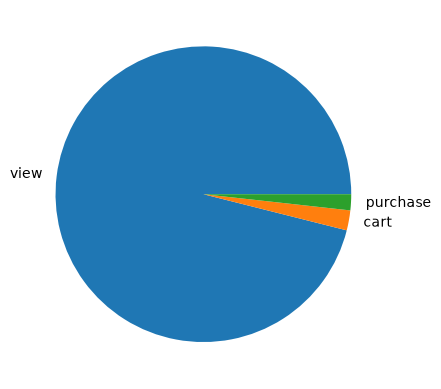

In [28]:
event_cnt = con.sql("""
        SELECT event_type, 
            COUNT(*) as cnt, 
            ROUND(COUNT(*) / SUM(COUNT(*)) OVER() * 100, 2) AS pct
        FROM events
        GROUP BY event_type
        """).df()
print(event_cnt)
plt.pie(event_cnt['cnt'], labels=event_cnt['event_type'])
plt.show()

### Сделаем строгую воронку этапов по сессиям

In [31]:
session_funnel = con.sql("""
        WITH views AS(
            SELECT user_session, MIN(event_time) AS t_view
            FROM events 
            WHERE event_type='view'
            GROUP BY user_session
        ),
        carts AS(
            SELECT e.user_session, MIN(e.event_time) AS t_cart
            FROM events e JOIN views v USING(user_session)
            WHERE e.event_type='cart' AND e.event_time > v.t_view
            GROUP BY e.user_session
        ),
        purchase AS(
            SELECT e.user_session, MIN(e.event_time) AS t_purchase
            FROM events e JOIN carts c USING(user_session)
            WHERE e.event_type='purchase' AND e.event_time > c.t_cart
            GROUP BY e.user_session
        )
        
        SELECT (SELECT COUNT(*) FROM views) as viewed,
               (SELECT COUNT(*) FROM carts) as carted,
               (SELECT COUNT(*) FROM purchase) as purchased
        """).df()

    viewed  carted  purchased
0  9242653  569877     288767
   viewed  carted  purchased  cart_to_purchase
0   99.98     6.2        3.1              50.7


<Axes: >

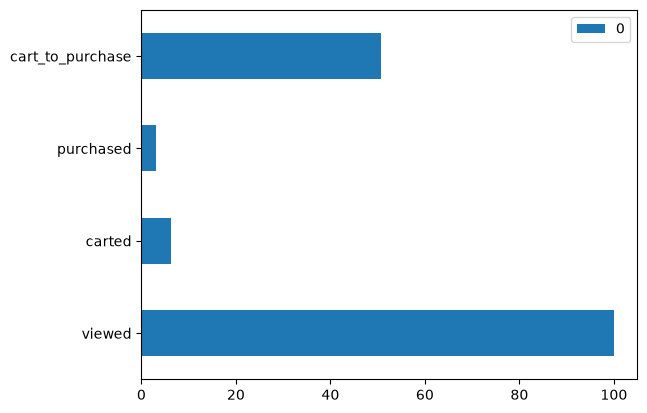

In [61]:
print(session_funnel)

pct_session_funnel = session_funnel.copy()

pct_session_funnel['viewed']=(session_funnel['viewed']/unique_session['cnt_of_session']).round(4)*100
pct_session_funnel['carted']=(session_funnel['carted']/session_funnel['viewed']).round(3)*100
pct_session_funnel['purchased']=(session_funnel['purchased']/session_funnel['viewed']).round(3)*100
pct_session_funnel['cart_to_purchase']=(session_funnel['purchased']/session_funnel['carted']).round(3)*100


print(pct_session_funnel)
pct_session_funnel.T.plot.barh()  

Не забываем закрывать соединение с duckdb

In [ ]:
con.close()